# Notebook 34 — Nested probability calibration and coverage-matched entry research

**Question:** Do chronological out-of-fold stacking models select better Up-class entries than a full-history Random Forest **at comparable entry coverage**?

This notebook performs a chronological **inner calibration split** inside each outer training fold. The inner models predict the later calibration period. We fit a binary Platt mapping and choose target-coverage thresholds **using only calibration-period labels/scores**. We then refit the base and meta models on all available outer-training history and apply the frozen calibration mapping and thresholds to the untouched outer validation fold.

**Important:** Calibration mappings are fitted using inner-model predictions, then transferred to separately refitted outer models. Probability distributions may shift; report actual coverage rather than assuming it equals the target. The results are development-only; the previously closed historical holdout and prospective prediction ledger are not accessed.

Entry policy: rank by **class-1 probability alone** (no argmax requirement); subtract 10 bps per selected entry. This policy differs from Notebook 33's `argmax==1` plus fixed probability threshold and should not be compared without accounting for the change.

In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
if not (ROOT/'src').exists():raise FileNotFoundError('Open inside stock_ml_dynamic repository')
sys.path.insert(0,str(ROOT/'src'))
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
from stock_ml_dynamic.pooled_models import load_master
from stock_ml_dynamic.coverage_calibration_research import run_research
SEED=42
N_OUTER=3
OOF_WINDOWS=5
CAP=60000
TREES=200
LEAF=20
CLIP=(.005,.995)
COVERAGES=(.05,.10,.15,.20,.25)
COST_BPS=10
CALIBRATION_FRACTION=.25
OUTPUT=ROOT/'artifacts'/'notebook34_calibration_coverage'
print('Repository:',ROOT)


Repository: /home/oem/Documents/github/stock_ml_dynamic


## Load the same 1d master-table artifact as Notebook 33

In [2]:
source=ROOT/'artifacts'/'master_tables'/'1d'
required=('master_labeled.parquet','latest_inference.parquet','transformers.joblib','manifest.json')
missing=[str(source/name) for name in required if not (source/name).exists()]
if missing:raise FileNotFoundError('Missing master-table artifacts: '+', '.join(missing)+'; rerun Notebook 03 from repository root or move notebooks/artifacts/master_tables/1d to artifacts/master_tables/1d')
master,latest,bundle,manifest=load_master(source)
print('Master:',master.shape,'Latest:',latest.shape,'Tickers:',master.symbol.nunique())
print('Date range:',master.bar_timestamp.min(),master.bar_timestamp.max())


Master: (431299, 27) Latest: (220, 27) Tickers: 220
Date range: 2018-11-28 00:00:00+00:00 2026-11-11 00:00:00+00:00


## Run nested chronological calibration experiment

Expect roughly twice the model-fitting workload of Notebook 33. The three outer folds each run an inner calibration experiment and an outer validation experiment. No validation labels are used to fit models, calibrators, or thresholds.

In [3]:
result=run_research(master,n_outer=N_OUTER,windows=OOF_WINDOWS,cap=CAP,trees=TREES,
                    leaf=LEAF,seed=SEED,clip=CLIP,coverages=COVERAGES,
                    cost_bps=COST_BPS,calibration_fraction=CALIBRATION_FRACTION,
                    output_dir=OUTPUT)
policies=result['policies'];audit=result['audit'];reliability=result['reliability'];preds=result['predictions']
print('Development cutoff:',result['cutoff'],'Features:',result['feature_count'])
print('Policy rows:',len(policies),'Validation predictions:',len(preds))
display(audit)


/home/oem/Documents/github/stock_ml_dynamic/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/oem/Documents/github/stock_ml_dynamic/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/home/oem/Documents/github/stock_ml_dynamic/.venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warning

Development cutoff: 2025-04-09 00:00:00+00:00 Features: 87
Policy rows: 90 Validation predictions: 935004


,fold,fit_rows,cal_rows,outer_train_rows,outer_valid_rows,latest_fit_outcome,earliest_cal_bar,latest_outer_train_outcome,earliest_outer_valid_bar,inner_oof_windows,outer_oof_windows
0,1,134112,46067,180395,51646,2021-07-22 00:00:00+00:00,2021-07-23 00:00:00+00:00,2022-05-26 00:00:00+00:00,2022-05-27 00:00:00+00:00,5,5
1,2,173017,59024,232258,51863,2022-04-07 00:00:00+00:00,2022-04-08 00:00:00+00:00,2023-05-10 00:00:00+00:00,2023-05-11 00:00:00+00:00,5,5
2,3,212077,72044,284338,52325,2022-12-23 00:00:00+00:00,2022-12-27 00:00:00+00:00,2024-04-24 00:00:00+00:00,2024-04-25 00:00:00+00:00,5,5


## Chronological leakage assertions

In [4]:
assert (pd.to_datetime(audit.latest_fit_outcome,utc=True)<pd.to_datetime(audit.earliest_cal_bar,utc=True)).all()
assert (pd.to_datetime(audit.latest_outer_train_outcome,utc=True)<pd.to_datetime(audit.earliest_outer_valid_bar,utc=True)).all()
assert audit.inner_oof_windows.eq(OOF_WINDOWS).all()
assert audit.outer_oof_windows.eq(OOF_WINDOWS).all()
print('PASS: calibration and outer validation are strictly after their respective training labels.')


PASS: calibration and outer validation are strictly after their respective training labels.


## Policy comparison at calibration-derived target coverage

coverage  up_precision  \
target_coverage model             calibration                           
0.05            full_history_rf   platt        0.026473      0.476859   
                                  raw          0.026473      0.476859   
                oof_meta_logistic platt        0.029246      0.444713   
                                  raw          0.029246      0.444713   
                oof_meta_rf       platt        0.071988      0.433459   
                                  raw          0.071988      0.433459   
0.10            full_history_rf   platt        0.069668      0.463088   
                                  raw          0.069668      0.463088   
                oof_meta_logistic platt        0.065591      0.461709   
                                  raw          0.065591      0.461709   
                oof_meta_rf       platt        0.130553      0.457001   
                                  raw          0.130553      0.457001   
0.15            full_history_rf   platt        0.110735      0.458021   
                                  raw          0.110735      0.458021   
                oof_meta_logistic platt        0.097531      0.472826   
                                  raw          0.097531      0.472826   
                oof_meta_rf       platt        0.149108      0.460678   
                                  raw          0.149108      0.460678   
0.20            full_history_rf   platt        0.147191      0.457990   
                                  raw          0.147191      0.457990   
                oof_meta_logistic platt        0.125216      0.479331   
                                  raw          0.125216      0.479331   
                oof_meta_rf       platt        0.195785      0.459262   
                                  raw          0.195785      0.459262   
0.25            full_history_rf   platt        0.182885      0.454236   
                                  raw          0.182885      0.454236   
                oof_meta_logistic platt        0.152894      0.471238   
                                  raw          0.152894      0.471238   
                oof_meta_rf       platt        0.218011      0.458596   
                                  raw          0.218011      0.458596   

                                               mean_net   entry_count  \
target_coverage model             calibration                           
0.05            full_history_rf   platt        0.000137   1379.000000   
                                  raw          0.000137   1379.000000   
                oof_meta_logistic platt       -0.002246   1527.333333   
                                  raw         -0.002246   1527.333333   
                oof_meta_rf       platt       -0.002492   3766.333333   
                                  raw         -0.002492   3766.333333   
0.10            full_history_rf   platt        0.000551   3624.333333   
                                  raw          0.000551   3624.333333   
                oof_meta_logistic platt       -0.000432   3419.000000   
                                  raw         -0.000432   3419.000000   
                oof_meta_rf       platt        0.000165   6800.333333   
                                  raw          0.000165   6800.333333   
0.15            full_history_rf   platt        0.000460   5758.666667   
                                  raw          0.000460   5758.666667   
                oof_meta_logistic platt       -0.000816   5080.000000   
                                  raw         -0.000816   5080.000000   
                oof_meta_rf       platt        0.000248   7761.666667   
                                  raw          0.000248   7761.666667   
0.20            full_history_rf   platt        0.000420   7654.333333   
                                  raw          0.000420   7654.333333   
                oof_meta_logistic platt        0.001909   6520.666667   
                               

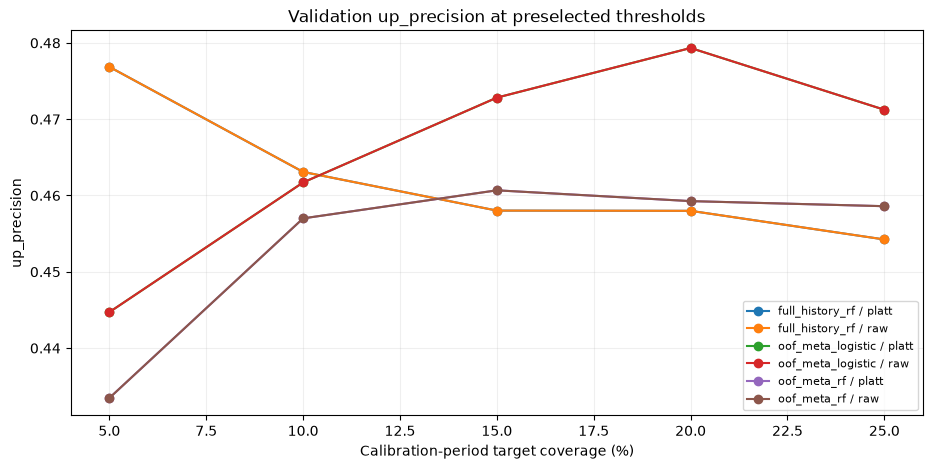

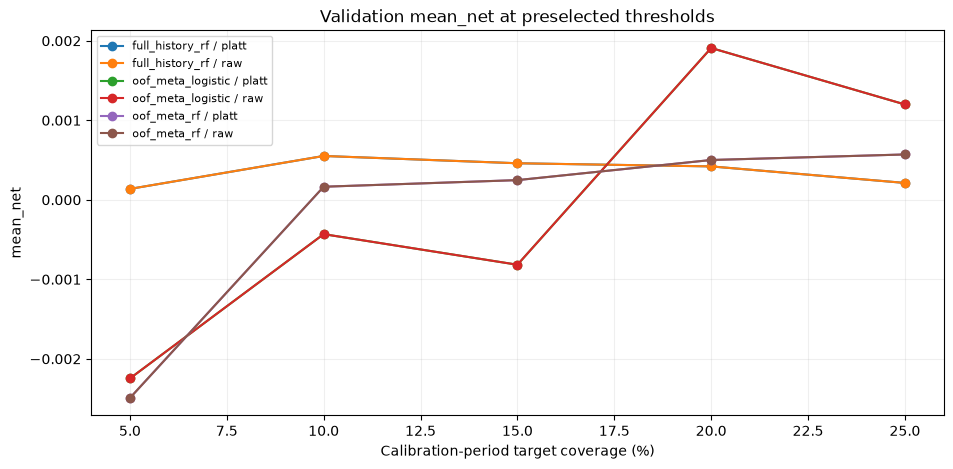

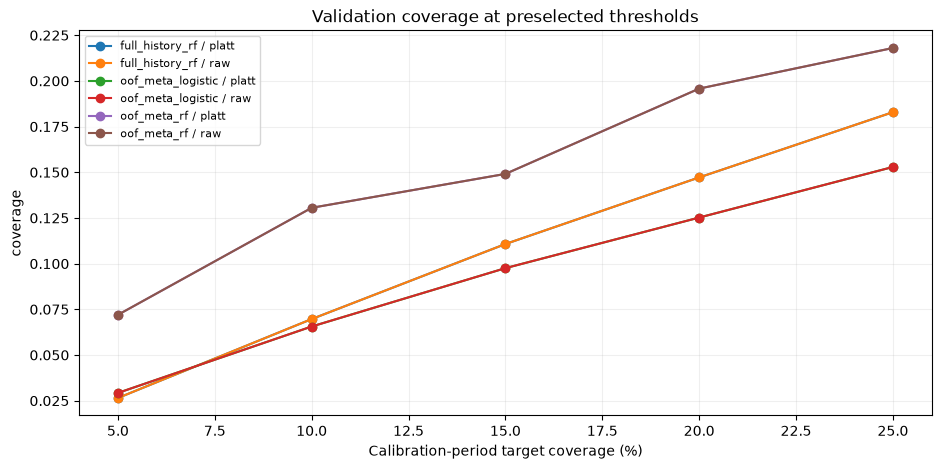

In [5]:
cols=['coverage','up_precision','mean_net','entry_count','hit_rate_net','brier_up','binary_logloss']
summary=policies.groupby(['target_coverage','model','calibration'])[cols].mean().round(6)
display(summary)
for metric in ['up_precision','mean_net','coverage']:
    fig,ax=plt.subplots(figsize=(11,5))
    for (model,calibration),group in policies.groupby(['model','calibration']):
        g=group.groupby('target_coverage')[metric].mean()
        ax.plot(g.index*100,g.values,marker='o',label=f'{model} / {calibration}')
    ax.set(xlabel='Calibration-period target coverage (%)',ylabel=metric,title=f'Validation {metric} at preselected thresholds')
    ax.legend(fontsize=8);ax.grid(alpha=.2);plt.show()


## Paired comparisons with the full-history RF at the same target coverage

These are **target-coverage matched** comparisons, not guaranteed exact realized-coverage matches. Check the actual validation coverage before interpreting precision differences.

In [6]:
base=policies.loc[policies.model.eq('full_history_rf')].set_index(['fold','target_coverage','calibration'])
paired=[]
for model,g in policies.groupby('model'):
    if model=='full_history_rf':continue
    g=g.set_index(['fold','target_coverage','calibration'])
    for metric in ['up_precision','mean_net','coverage','brier_up','binary_logloss']:
        delta=(g[metric]-base[metric]).dropna()
        for (fold,coverage,cal),value in delta.items():
            paired.append(dict(fold=fold,target_coverage=coverage,calibration=cal,model=model,
                               metric=metric,difference=value))
paired=pd.DataFrame(paired)
display(paired.groupby(['target_coverage','calibration','model','metric']).difference.agg(['mean','min','max']).round(6))


mean  \
target_coverage calibration model             metric                     
0.05            platt       oof_meta_logistic binary_logloss -0.000133   
                                              brier_up       -0.000065   
                                              coverage        0.002774   
                                              mean_net       -0.001256   
                                              up_precision   -0.006040   
...                                                                ...   
0.25            raw         oof_meta_rf       binary_logloss -0.001646   
                                              brier_up       -0.000760   
                                              coverage        0.035127   
                                              mean_net        0.000358   
                                              up_precision    0.004361   

                                                                   min  \
target_coverage calibration model             metric                     
0.05            platt       oof_meta_logistic binary_logloss -0.001326   
                                              brier_up       -0.000627   
                                              coverage       -0.011908   
                                              mean_net       -0.001534   
                                              up_precision   -0.017353   
...                                                                ...   
0.25            raw         oof_meta_rf       binary_logloss -0.004200   
                                              brier_up       -0.001924   
                                              coverage       -0.052272   
                                              mean_net       -0.000529   
                                              up_precision   -0.006238   

                                                                   max  
target_coverage calibration model             metric                    
0.05            platt       oof_meta_logistic binary_logloss  0.000605  
                                              brier_up        0.000281  
                                              coverage        0.023545  
                                              mean_net       -0.000977  
                                              up_precision    0.005272  
...                                                                ...  
0.25            raw         oof_meta_rf       binary_logloss -0.000046  
                                              brier_up       -0.000016  
                                              coverage        0.123940  
                                              mean_net        0.001663  
                                              up_precision    0.023322  

[100 rows x 3 columns]

## Calibration reliability curves and Brier scores

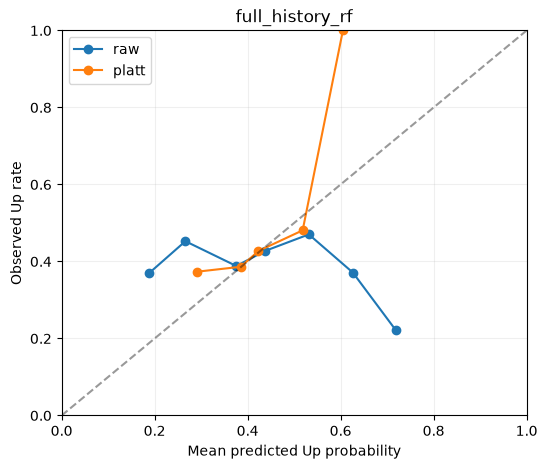

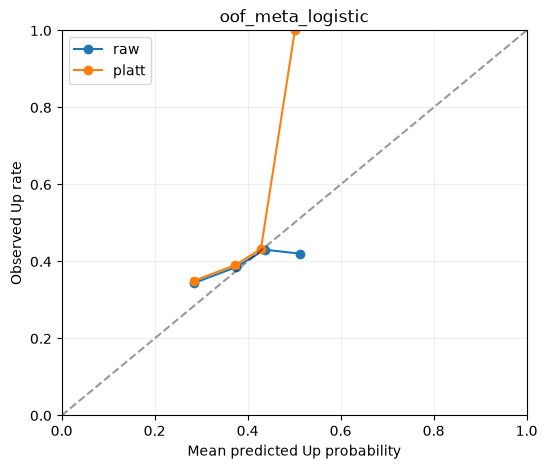

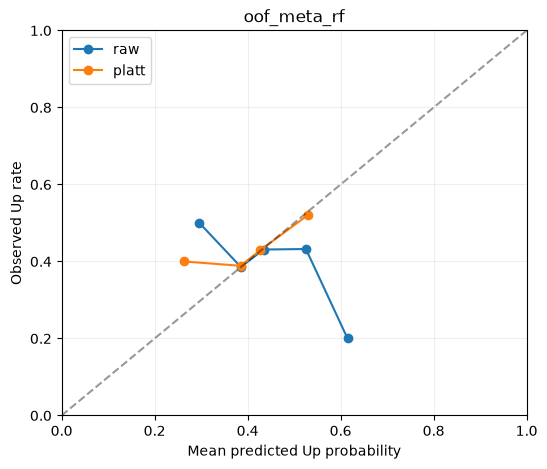

brier_up  binary_logloss
model             calibration                          
full_history_rf   platt        0.243125        0.679333
                  raw          0.243840        0.680858
oof_meta_logistic platt        0.243060        0.679201
                  raw          0.243019        0.679099
oof_meta_rf       platt        0.243084        0.679240
                  raw          0.243080        0.679212

In [7]:
for model in ['full_history_rf','oof_meta_logistic','oof_meta_rf']:
    fig,ax=plt.subplots(figsize=(6,5))
    for variant in ['raw','platt']:
        sub=reliability.loc[(reliability.model==model)&(reliability.subset==variant)]
        agg=sub.groupby('bin').apply(lambda g:pd.Series({
            'n':g.n.sum(),
            'pred':np.average(g.predicted_up.dropna(),weights=g.loc[g.predicted_up.notna(),'n']) if g.predicted_up.notna().any() else np.nan,
            'actual':np.average(g.observed_up.dropna(),weights=g.loc[g.observed_up.notna(),'n']) if g.observed_up.notna().any() else np.nan
        }),include_groups=False)
        ax.plot(agg['pred'],agg['actual'],marker='o',label=variant)
    ax.plot([0,1],[0,1],'k--',alpha=.4)
    ax.set(xlim=(0,1),ylim=(0,1),xlabel='Mean predicted Up probability',ylabel='Observed Up rate',title=model)
    ax.legend();ax.grid(alpha=.2);plt.show()
display(policies.groupby(['model','calibration'])[['brier_up','binary_logloss']].mean().round(6))


## Up precision and net returns by predicted-probability decile

Decile boundaries here are computed on the outer validation scores for **descriptive diagnostics only**. They must not be used as deployed trading thresholds.

up_precision  mean_net  avg_probability
model             calibration decile                                         
full_history_rf   platt       1            0.37904  -0.00042          0.37716
                              2            0.38887  -0.00093          0.39477
                              3            0.39975  -0.00076          0.40185
                              4            0.41007  -0.00096          0.40769
                              5            0.41848  -0.00057          0.41303
                              6            0.42564  -0.00043          0.41813
                              7            0.42588  -0.00036          0.42331
                              8            0.44075  -0.00009          0.42908
                              9            0.44343   0.00022          0.43766
                              10           0.46229   0.00044          0.45892
                  raw         1            0.37904  -0.00042          0.34901
                              2            0.38887  -0.00093          0.38346
                              3            0.39975  -0.00076          0.39755
                              4            0.41007  -0.00096          0.40915
                              5            0.41848  -0.00057          0.41963
                              6            0.42564  -0.00043          0.42962
                              7            0.42588  -0.00036          0.43983
                              8            0.44075  -0.00009          0.45139
                              9            0.44343   0.00022          0.46900
                              10           0.46229   0.00044          0.51228
oof_meta_logistic platt       1            0.36265  -0.00092          0.35498
                              2            0.39026  -0.00074          0.38235
                              3            0.41549  -0.00028          0.39490
                              4            0.41035  -0.00060          0.40422
                              5            0.42040  -0.00047          0.41211
                              6            0.41594  -0.00077          0.41913
                              7            0.42513  -0.00056          0.42559
                              8            0.43711  -0.00036          0.43172
                              9            0.44862   0.00003          0.43832
                              10           0.46827   0.00082          0.44954
                  raw         1            0.36265  -0.00092          0.35599
                              2            0.39026  -0.00074          0.38844
                              3            0.41549  -0.00028          0.40327
                              4            0.41035  -0.00060          0.41410
                              5            0.42040  -0.00047          0.42313
                              6            0.41594  -0.00077          0.43113
                              7            0.42513  -0.00056          0.43854
                              8            0.43711  -0.00036          0.44573
                              9            0.44862   0.00003          0.45398
                              10           0.46827   0.00082          0.46916
oof_meta_rf       platt       1            0.35666  -0.00121          0.37794
                              2            0.39159  -0.00082          0.39205
                              3            0.41371  -0.00024          0.39880
                              4            0.41480  -0.00054          0.40577
                              5            0.42063  -0.00040          0.41461
                              6            0.42449  -0.00046          0.42146
                              7            0.42152  -0.00071          0.42807
                              8            0.43507  -0.00021          0.43442
                              9            0.45458   0.00055          0.44019
                              10           0.46117   0.00021

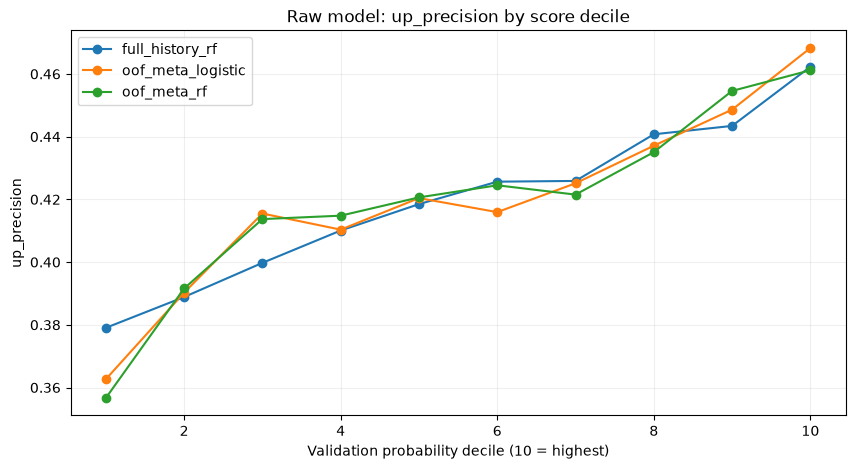

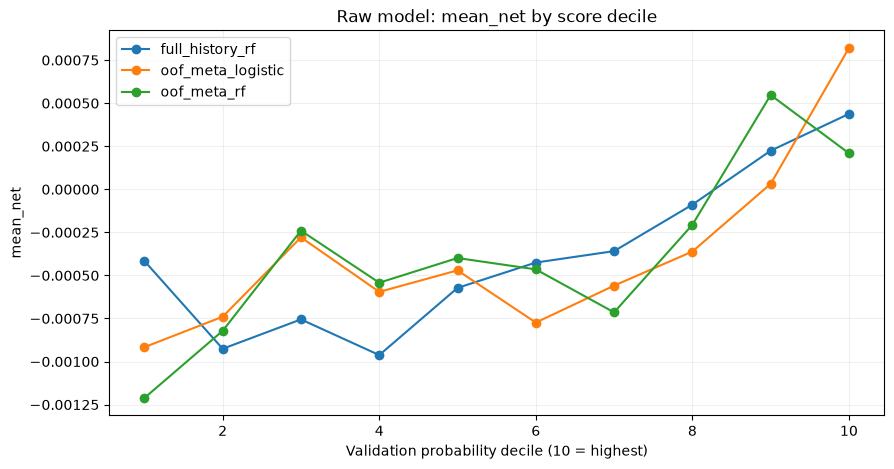

In [8]:
decile_rows=[]
for (fold,model,variant),g in preds.groupby(['fold','model','calibration']):
    g=g.copy()
    g['decile']=pd.qcut(g.up_probability.rank(method='first'),10,labels=False)+1
    for decile,h in g.groupby('decile'):
        decile_rows.append(dict(fold=fold,model=model,calibration=variant,decile=decile,
                                n=len(h),up_precision=(h.direction==1).mean(),
                                mean_net=(h.next_return-COST_BPS/10000).mean(),
                                avg_probability=h.up_probability.mean()))
deciles=pd.DataFrame(decile_rows)
display(deciles.groupby(['model','calibration','decile'])[['up_precision','mean_net','avg_probability']].mean().round(5))
for metric in ['up_precision','mean_net']:
    fig,ax=plt.subplots(figsize=(10,5))
    for model,g in deciles.loc[deciles.calibration.eq('raw')].groupby('model'):
        h=g.groupby('decile')[metric].mean()
        ax.plot(h.index,h.values,marker='o',label=model)
    ax.set(xlabel='Validation probability decile (10 = highest)',ylabel=metric,title=f'Raw model: {metric} by score decile')
    ax.legend();ax.grid(alpha=.2);plt.show()


## Decision checklist

- Compare **paired** Up precision and mean net returns at 5–25% target coverage across all three folds.
- Examine **realized** coverage gaps; large gaps mean threshold transfer is unstable.
- Check whether Platt calibration improves binary Brier/log loss. Calibration alone cannot improve ranking within a fold because sigmoid Platt mapping is monotone.
- Treat validation deciles as exploratory, not as thresholds selected without leakage.
- Do **not** promote a trading strategy based on these development results alone. The historical final holdout stays closed.

In [9]:
print('Saved results:',OUTPUT)
print('Historical final holdout: not accessed. Prospective prediction ledger: unchanged.')


Saved results: /home/oem/Documents/github/stock_ml_dynamic/artifacts/notebook34_calibration_coverage
Historical final holdout: not accessed. Prospective prediction ledger: unchanged.
